### Exercise 1

Gel electrophoresis is an analysis method used in all disciplines of the life sciences.
The results of gel electrophoresis indicate the relative sizes of the fragments, which is useful for restriction mapping and for analyzing PCR fragments.

1. Take an arbitrary DNA sequence from NCBI (National Center for Biotechnology Information), between 1000 and 3000 nucleotides (letters).
2. Take 10 random samples from this sequence, between 100 and 3000 bases.
3. Store these samples in an array.
4. Simulate the migration of these DNA segments on the electrophoresis gel, based on their molecular weight (number of nucleotides).

**Note:** Short DNA fragments meet small friction forces and travel fast through the electrophoresis gel, while long DNA fragments exhibit a high friction force and travel slowly through the gel.

Sequence used: *Cloning vector pUC19c*, complete sequence (NCBI **L09137.2**, 2,686 bp).

In [1]:
import math
import random

import matplotlib.pyplot as plt


def read_fasta(path):
    """Return the sequence from a FASTA file (header lines starting with '>' are skipped)."""
    with open(path) as f:
        return "".join(line.strip() for line in f if not line.startswith(">")).upper()


def take_samples(dna, n=10, min_len=100, max_len=3000, seed=42):
    """Cut n random fragments of min_len-max_len bases out of the sequence.
    max_len is capped at the sequence length, since a fragment cannot be longer than the sequence."""
    rng = random.Random(seed)
    max_len = min(max_len, len(dna))
    samples = []
    for _ in range(n):
        length = rng.randint(min_len, max_len)
        start = rng.randint(0, len(dna) - length)
        samples.append(dna[start:start + length])
    return samples


dna = read_fasta("puc19.fasta")
samples = take_samples(dna)          # step 3: the samples are stored in an array (list)

print("Sequence: Cloning vector pUC19c (L09137.2)")
print(f"Length = {len(dna):,} nucleotides")
print(f"Samples = {len(samples)}")

Sequence: Cloning vector pUC19c (L09137.2)
Length = 2,686 nucleotides
Samples = 10


#### Molecular weight of each fragment

On the gel the fragments are double-stranded DNA, so the molecular weight is approximately

$$MW_{dsDNA} \approx N_{bp} \times 617.96 + 36.04 \ \text{g/mol}$$

The weight is proportional to the number of base pairs, so the size in bp is what decides the migration speed.

In [2]:
def ds_molecular_weight(n_bp):
    """Approximate molecular weight (g/mol = Da) of a double-stranded DNA fragment."""
    return n_bp * 617.96 + 36.04


print(f"{'Sample':>6} | {'Length (bp)':>11} | {'MW (kDa)':>9} | start of the fragment")
print("-" * 60)
for i, s in enumerate(samples, 1):
    print(f"{i:>6} | {len(s):>11,} | {ds_molecular_weight(len(s)) / 1000:>9.1f} | {s[:25]}...")

Sample | Length (bp) |  MW (kDa) | start of the fragment
------------------------------------------------------------
     1 |         556 |     343.6 | AGGGCGCGTCAGCGGGTGTTGGCGG...
     2 |       1,226 |     757.7 | ACAATTCCACACAACATACGAGCCG...
     3 |       1,014 |     626.6 | GGGCCTCTTCGCTATTACGCCAGCT...
     4 |         519 |     320.8 | GGGTTTTCCCAGTCACGACGTTGTA...
     5 |       2,518 |    1556.1 | CGTCAGCGGGTGTTGGCGGGTGTCG...
     6 |         230 |     142.2 | GGCGGGTGTCGGGGCTGGCTTAACT...
     7 |         483 |     298.5 | ATCACAAAAATCGACGCTCAAGTCA...
     8 |       1,052 |     650.1 | CCCTTCGGGAAGCGTGGCGCTTTCT...
     9 |       2,565 |    1585.1 | CGCGTTTCGGTGATGACGGTGAAAA...
    10 |       2,398 |    1481.9 | CAGGGCGCGTCAGCGGGTGTTGGCG...


#### Migration model

In an agarose gel the distance travelled by a linear DNA fragment decreases (approximately linearly) with the
**logarithm** of its size: the larger the fragment, the more friction it meets in the pores of the gel, so the slower it moves.
We use

$$v(N) = k \cdot (\log_{10} N_{max} - \log_{10} N), \qquad d(t) = v(N) \cdot t$$

where $N_{max} = 20\,000$ bp is a size that practically does not move and $k$ is set so that the smallest fragment of the
ladder (100 bp) reaches the bottom of the gel at the end of the run. A DNA ladder (fragments of known size) is run in the first lane, like in a real experiment.

In [3]:
LADDER = [100, 200, 300, 400, 500, 700, 1000, 1500, 2000, 3000]   # known sizes (bp)
N_MAX = 20_000            # a fragment this large practically does not move
GEL_LENGTH = 10.0         # cm, from the wells to the end of the gel
RUN_TIME = 40             # minutes
K = GEL_LENGTH / (RUN_TIME * (math.log10(N_MAX) - math.log10(min(LADDER))))


def distance(n_bp, t):
    """Distance (cm) travelled by a fragment of n_bp after t minutes: small fragments move faster."""
    return min(K * (math.log10(N_MAX) - math.log10(n_bp)) * t, GEL_LENGTH)


lengths = [len(s) for s in samples]
print(f"{'Sample':>6} | {'Length (bp)':>11} | {'Speed (cm/min)':>14} | {'Distance after ' + str(RUN_TIME) + ' min (cm)':>26}")
print("-" * 68)
for i, n in sorted(enumerate(lengths, 1), key=lambda x: x[1]):
    print(f"{i:>6} | {n:>11,} | {distance(n, 1):>14.3f} | {distance(n, RUN_TIME):>26.2f}")

Sample | Length (bp) | Speed (cm/min) | Distance after 40 min (cm)
--------------------------------------------------------------------
     6 |         230 |          0.211 |                       8.43
     7 |         483 |          0.176 |                       7.03
     4 |         519 |          0.172 |                       6.89
     1 |         556 |          0.169 |                       6.76
     3 |       1,014 |          0.141 |                       5.63
     8 |       1,052 |          0.139 |                       5.56
     2 |       1,226 |          0.132 |                       5.27
    10 |       2,398 |          0.100 |                       4.00
     5 |       2,518 |          0.098 |                       3.91
     9 |       2,565 |          0.097 |                       3.88


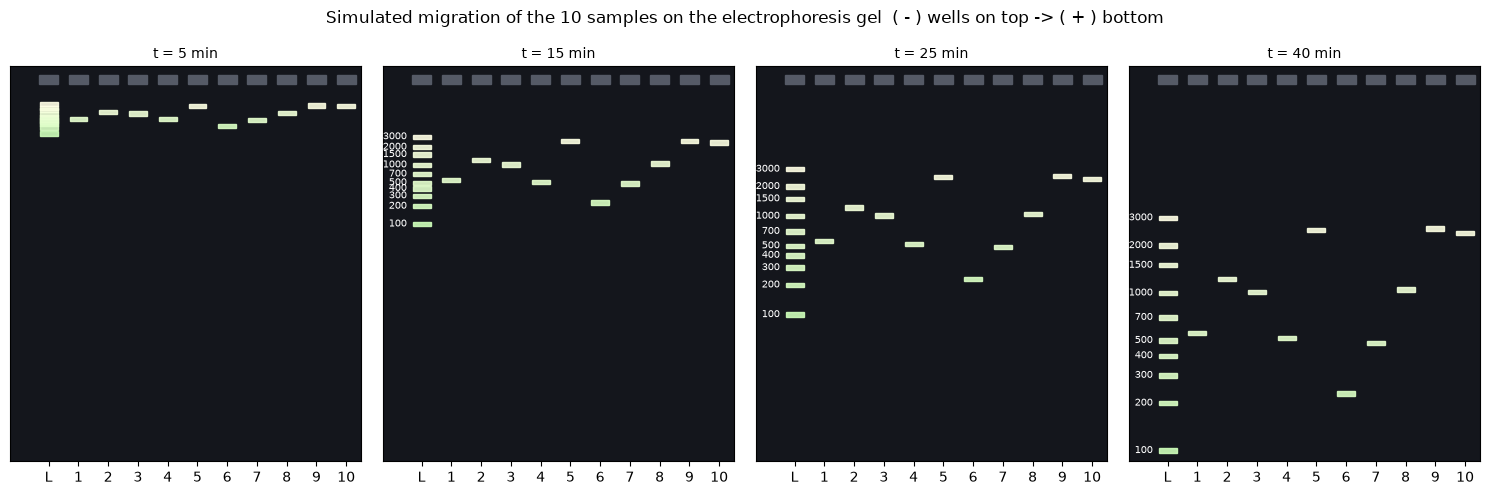

In [4]:
def draw_gel(ax, t, show_labels=True):
    """Draw the gel after t minutes: lane 0 = ladder (L), lanes 1-10 = the samples."""
    lanes = [LADDER] + [[n] for n in lengths]
    ax.set_facecolor("#14161c")
    for x, sizes in enumerate(lanes):
        # well at the top
        ax.add_patch(plt.Rectangle((x - 0.32, -0.35), 0.64, 0.25, color="#555a66"))
        for n in sizes:
            y = distance(n, t)
            bright = 0.55 + 0.45 * (math.log10(n) / math.log10(max(LADDER)))   # bigger fragment -> more DNA -> brighter band
            ax.add_patch(plt.Rectangle((x - 0.3, y - 0.06), 0.6, 0.12, color=(bright, 1.0, bright * 0.9), alpha=0.9))
            if show_labels and x == 0:
                ax.text(-0.5, y, f"{n}", color="white", fontsize=7, ha="right", va="center")
    ax.set_xlim(-1.3, len(lanes) - 0.5)
    ax.set_ylim(GEL_LENGTH + 0.3, -0.6)              # wells on top, migration downwards
    ax.set_xticks(range(len(lanes)), ["L"] + [str(i) for i in range(1, len(lengths) + 1)])
    ax.set_yticks([])
    ax.set_title(f"t = {t} min", fontsize=10)


# Migration over time
fig, axes = plt.subplots(1, 4, figsize=(15, 5), facecolor="white")
for ax, t in zip(axes, [5, 15, 25, RUN_TIME]):
    draw_gel(ax, t, show_labels=t >= 15)
fig.suptitle("Simulated migration of the 10 samples on the electrophoresis gel  ( - ) wells on top -> ( + ) bottom", fontsize=12)
plt.tight_layout()
plt.show()

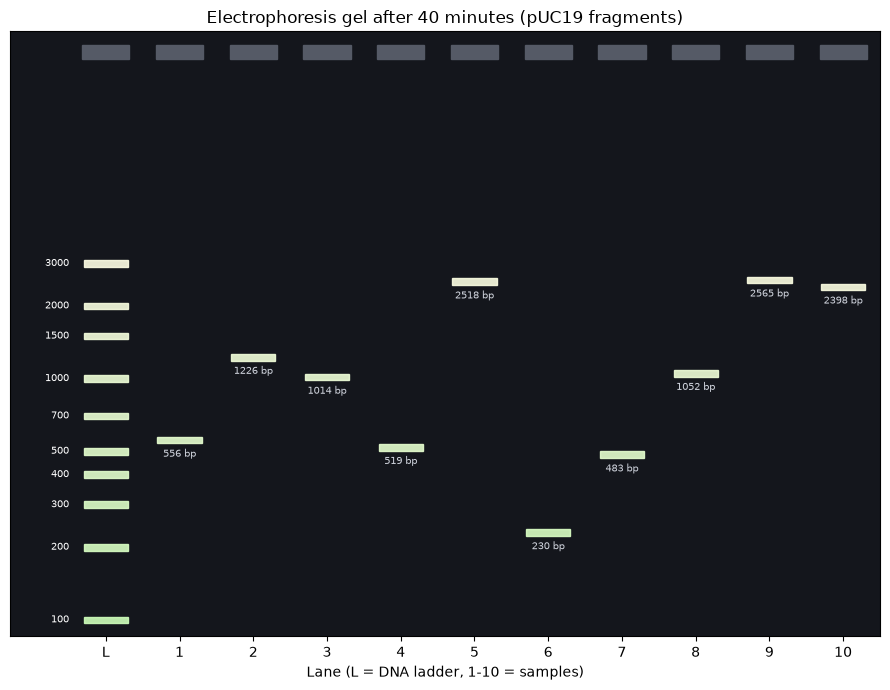

In [5]:
# Final gel, with the size of each band written next to it
fig, ax = plt.subplots(figsize=(9, 7))
draw_gel(ax, RUN_TIME)
for x, n in enumerate(lengths, 1):
    ax.text(x, distance(n, RUN_TIME) + 0.3, f"{n} bp", color="#cfd3dc", fontsize=7, ha="center")
ax.set_xlabel("Lane (L = DNA ladder, 1-10 = samples)")
ax.set_title(f"Electrophoresis gel after {RUN_TIME} minutes (pUC19 fragments)")
plt.tight_layout()
plt.show()

### Conclusion

- The 10 samples have different lengths, so they end up as bands at different heights in the gel.
- The **shortest fragments travel the farthest** (bottom of the gel) because they meet the smallest friction force; the
  **longest fragments stay close to the wells**.
- The distance depends on the logarithm of the size, so small fragments are well separated, while large fragments of
  similar size (e.g. 2000 vs 2500 bp) end up close together and are harder to tell apart.
- By comparing each band with the ladder lane (fragments of known size) we can estimate the size of an unknown fragment -
  this is how gel electrophoresis is used in practice (restriction mapping, checking PCR products).

### Exercise 2

Take an arbitrary DNA sequence from NCBI, between 1000 and 3000 nucleotides. Implement a software application that
detects **repetitions between 6 and 10 bases** in the DNA sequence. The length of the repeated unit is between **3 and 5** bases.

Sequence used: the same *Cloning vector pUC19c* (NCBI **L09137.2**, 2,686 bp) from Exercise 1.

#### Approach

We look for **tandem repeats**: a unit of 3-5 bases that is copied right after itself, so that the whole repeated
region has 6-10 bases:

| Unit length | Copies | Region length | Example |
|:-:|:-:|:-:|:--|
| 3 | 2 or 3 | 6 or 9 | `ACG ACG`, `ACG ACG ACG` |
| 4 | 2 | 8 | `CTCA CTCA` |
| 5 | 2 | 10 | `TTGCG TTGCG` |

For each unit length $u = 3, 4, 5$ we move along the sequence, take the $u$ bases starting at position $i$ as the unit and
count how many times it is copied back to back. If there are at least 2 copies and the region has 6-10 bases, it is a repetition.
Units made of a single base (e.g. `AAA`) are skipped, because `AAAAAA` is a run of one letter, not a repeated pattern.

In [6]:
UNIT_MIN, UNIT_MAX = 3, 5        # length of the repeated unit
REGION_MIN, REGION_MAX = 6, 10   # length of the whole repeated region


def find_tandem_repeats(dna, unit_min=UNIT_MIN, unit_max=UNIT_MAX, region_min=REGION_MIN, region_max=REGION_MAX):
    # Return a list of (start, unit, copies) for units of unit_min..unit_max bases copied back to back,
    # where the whole region has region_min..region_max bases.
    found = []
    for u in range(unit_min, unit_max + 1):
        i = 0
        while i + 2 * u <= len(dna):
            unit, copies = dna[i:i + u], 1
            while dna[i + copies * u:i + (copies + 1) * u] == unit:
                copies += 1
            if copies >= 2 and len(set(unit)) > 1 and region_min <= copies * u <= region_max:
                found.append((i, unit, copies))
                i += (copies - 1) * u + 1      # jump over this region
            else:
                i += 1
    return sorted(found)


tandems = find_tandem_repeats(dna)

print(f"Sequence length: {len(dna):,} nucleotides")
print(f"Repetitions found: {len(tandems)}\n")
print(f"{'#':>3} | {'Position':>8} | {'Unit':<5} | {'Copies':>6} | {'Length':>6} | Region (with 5 bases of context)")
print("-" * 80)
for idx, (i, unit, copies) in enumerate(tandems, 1):
    end = i + copies * len(unit)
    context = f"{dna[max(0, i - 5):i].lower()} {' '.join([unit] * copies)} {dna[end:end + 5].lower()}"
    print(f"{idx:>3} | {i + 1:>8} | {unit:<5} | {copies:>6} | {copies * len(unit):>6} | {context}")

Sequence length: 2,686 nucleotides
Repetitions found: 43

  # | Position | Unit  | Copies | Length | Region (with 5 bases of context)
--------------------------------------------------------------------------------
  1 |       14 | TGA   |      2 |      6 | ttcgg TGA TGA cggtg
  2 |      135 | GGCT  |      2 |      8 | gtcgg GGCT GGCT taact
  3 |      326 | TGC   |      2 |      6 | ggatg TGC TGC aaggc
  4 |      371 | ACG   |      2 |      6 | cagtc ACG ACG ttgta
  5 |      384 | ACG   |      2 |      6 | gtaaa ACG ACG gccag
  6 |      512 | ACA   |      2 |      6 | tccac ACA ACA tacga
  7 |      559 | TGAG  |      2 |      8 | cctaa TGAG TGAG ctaac
  8 |      581 | TTGCG |      2 |     10 | attaa TTGCG TTGCG ctcac
  9 |      732 | GCG   |      2 |      6 | cggct GCG GCG agcgg
 10 |      749 | CTCA  |      2 |      8 | atcag CTCA CTCA aaggc
 11 |     1213 | GCA   |      2 |      6 | cactg GCA GCA gccac
 12 |     1278 | GTG   |      2 |      6 | ttgaa GTG GTG gccta
 13 |     1303 | AG

In [7]:
# Summary by unit length
print(f"{'Unit length':>11} | {'Repetitions':>11} | {'Different units':>15} | Most common unit")
print("-" * 65)
for u in range(UNIT_MIN, UNIT_MAX + 1):
    of_u = [unit for _, unit, _ in tandems if len(unit) == u]
    top = max(set(of_u), key=of_u.count) if of_u else "-"
    print(f"{u:>11} | {len(of_u):>11} | {len(set(of_u)):>15} | {top} ({of_u.count(top)}x)")

Unit length | Repetitions | Different units | Most common unit
-----------------------------------------------------------------
          3 |          30 |              25 | GCG (2x)
          4 |          11 |              11 | AGTA (1x)
          5 |           2 |               2 | TTGCG (1x)


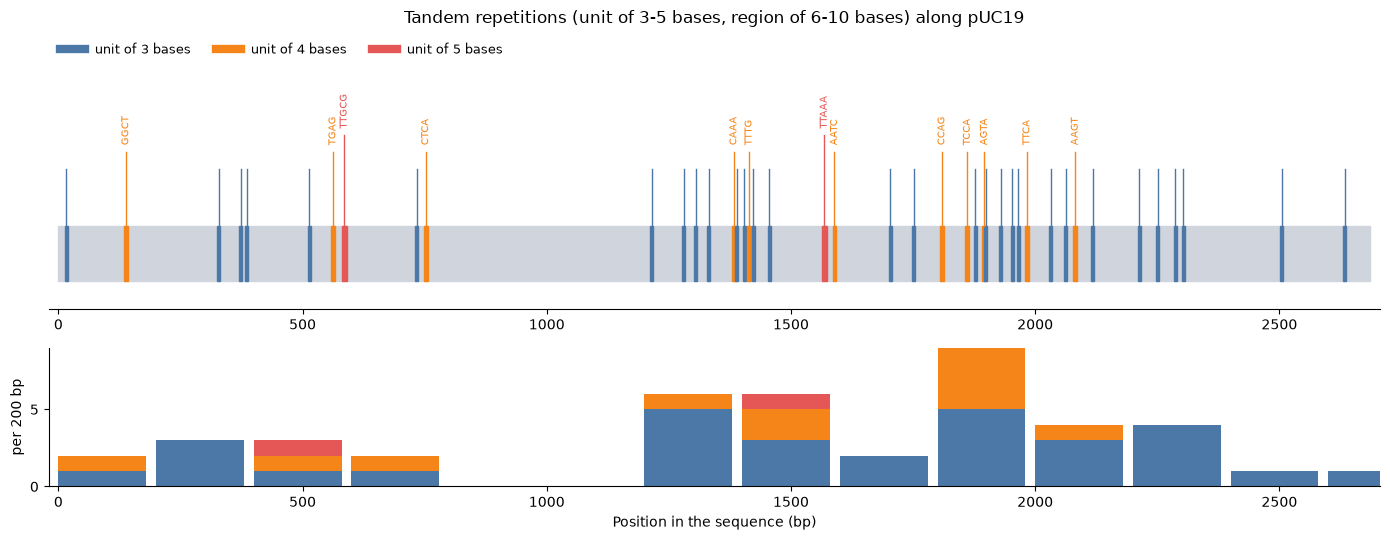

In [8]:
# Plot: where the repetitions are located in the sequence, coloured by the length of the unit
unit_colors = {3: "#4c78a8", 4: "#f58518", 5: "#e45756"}

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 5.5), gridspec_kw={"height_ratios": [2, 1]})

ax1.add_patch(plt.Rectangle((0, -0.2), len(dna), 0.4, color="#d0d4dc"))    # the whole sequence
for i, unit, copies in tandems:
    u = len(unit)
    ax1.add_patch(plt.Rectangle((i, -0.2), copies * u, 0.4, color=unit_colors[u]))
    ax1.plot([i + copies * u / 2] * 2, [0.2, 0.25 + u * 0.12], color=unit_colors[u], lw=1)
    if u >= 4:
        ax1.text(i + copies * u / 2, 0.3 + u * 0.12, unit, rotation=90, fontsize=7, ha="center", va="bottom", color=unit_colors[u])
for u, c in unit_colors.items():
    ax1.plot([], [], color=c, lw=6, label=f"unit of {u} bases")
ax1.set_xlim(-20, len(dna) + 20)
ax1.set_ylim(-0.4, 1.6)
ax1.set_yticks([])
ax1.spines[["top", "right", "left"]].set_visible(False)
ax1.legend(ncol=3, frameon=False, loc="upper left", fontsize=9)
ax1.set_title("Tandem repetitions (unit of 3-5 bases, region of 6-10 bases) along pUC19")

# number of repetitions in each 200 bp window
WINDOW = 200
starts = list(range(0, len(dna), WINDOW))
bottom = [0] * len(starts)
for u, c in unit_colors.items():
    counts = [sum(1 for i, unit, _ in tandems if len(unit) == u and s <= i < s + WINDOW) for s in starts]
    ax2.bar(starts, counts, width=WINDOW * 0.9, align="edge", bottom=bottom, color=c)
    bottom = [b + n for b, n in zip(bottom, counts)]
ax2.set_xlim(-20, len(dna) + 20)
ax2.set_xlabel("Position in the sequence (bp)")
ax2.set_ylabel(f"per {WINDOW} bp")
ax2.yaxis.get_major_locator().set_params(integer=True)
ax2.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

#### Repeated fragments of 6-10 bases anywhere in the sequence

As an extra, we also look for fragments of 6-10 bases that appear **more than once anywhere** in the sequence
(not necessarily next to each other). For every length $k$ we slide a window of $k$ bases over the sequence and store each
fragment with the list of positions where it starts. A fragment is dropped if it is only a part of a longer repeated
fragment found at the same places.

In [9]:
from collections import defaultdict


def find_repeated_fragments(dna, k_min=REGION_MIN, k_max=REGION_MAX):
    # Return {fragment: [start positions]} for every fragment of k_min..k_max bases that appears at least twice.
    repeats = {}
    for k in range(k_min, k_max + 1):
        positions = defaultdict(list)
        for i in range(len(dna) - k + 1):
            positions[dna[i:i + k]].append(i)
        repeats.update({s: p for s, p in positions.items() if len(p) > 1})
    return repeats


repeats = find_repeated_fragments(dna)
maximal = {s: p for s, p in repeats.items()
           if not any(len(t) > len(s) and len(q) == len(p) and s in t for t, q in repeats.items())}

print(f"{'Length':>6} | {'Repeated fragments':>18} | {'After removing sub-fragments':>28}")
print("-" * 60)
for k in range(REGION_MIN, REGION_MAX + 1):
    print(f"{k:>6} | {sum(len(s) == k for s in repeats):>18} | {sum(len(s) == k for s in maximal):>28}")

print("\nLongest repeated fragments (9-10 bases):\n")
print(f"{'Fragment':<10} | {'Length':>6} | {'Times':>5} | Positions (1-based)")
print("-" * 50)
for s, p in sorted(maximal.items(), key=lambda x: (-len(x[0]), x[1][0])):
    if len(s) >= 9:
        print(f"{s:<10} | {len(s):>6} | {len(p):>5} | {', '.join(str(x + 1) for x in p)}")

Length | Repeated fragments | After removing sub-fragments
------------------------------------------------------------
     6 |                590 |                          369
     7 |                217 |                          110
     8 |                 74 |                           42
     9 |                 22 |                           10
    10 |                  8 |                            8

Longest repeated fragments (9-10 bases):

Fragment   | Length | Times | Positions (1-based)
--------------------------------------------------
AAATACCGCA |     10 |     2 | 196, 222
GTGAGCAAAA |     10 |     2 | 810, 2415
AGCAAAAGGC |     10 |     2 | 813, 824
GCAAAAGGCC |     10 |     2 | 814, 825
CAAAAGGCCA |     10 |     2 | 815, 826
AAAAGGCCAG |     10 |     2 | 816, 827
AAAAAGGATC |     10 |     2 | 1442, 1539
AAAAGGATCT |     10 |     2 | 1443, 1540
GTGTGAAAT  |      9 |     2 | 191, 481
GTGCTGCAA  |      9 |     2 | 325, 1748
AGCCGGAAG  |      9 |     2 | 522, 1812
CGCTC

### Conclusion

- The application finds all the **tandem repetitions** in the sequence: a unit of 3-5 bases copied back to back, giving a
  repeated region of 6-10 bases. For each one it reports the position, the unit, the number of copies and the length.
- Most of the repetitions found have a unit of **3 bases** copied twice (6 bases). Longer units are rarer, because the chance
  that 4 or 5 bases are copied exactly right after themselves is much smaller ($1/4^4$ and $1/4^5$ instead of $1/4^3$).
- No unit was copied enough times to give a region longer than 10 bases, so pUC19 has no long microsatellites. This is
  expected for a cloning vector, where long repeats are avoided because they make the plasmid unstable.
- Looking for repeated fragments anywhere in the sequence gives many short repeats (6 bases appear again by chance) and only a
  few repeats of 9-10 bases, which are the more meaningful ones.